In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt

# Numerical Differentiation

$$
\begin{align}
y(t) = Kx(t)
&= \int_0^t x(s) ds\\
&= \int_0^t k(t, s) x(s) ds, \quad k(s, t) =
    \begin{cases}
        1 \quad s < t\\
        0 \quad s > t\\
    \end{cases}
\end{align}

$$

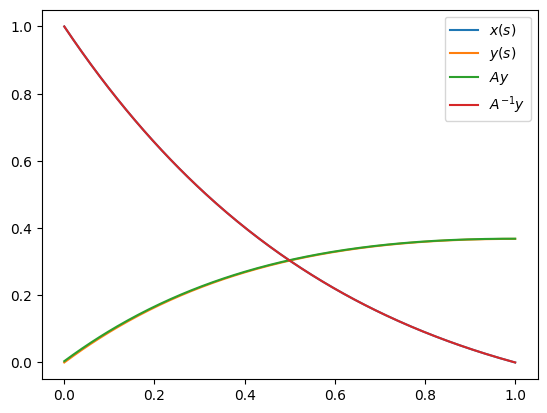

In [2]:
def y(s):
    return s * np.exp(-s)

def x(s):
    return (1-s) * np.exp(-s)

# Construct grid
N = 256
h = 1.0 / N
s = np.linspace(0, 1, N)

xvec = x(s)
# Backward Euler
A = np.tril(np.ones(N)) * h

yfwd = A @ xvec
xbwk = np.linalg.solve(A, yfwd)
plt.plot(s, x(s), label='$x(s)$')
plt.plot(s, y(s), label='$y(s)$')
plt.plot(s, yfwd, label='$Ay$')
plt.plot(s, xbwk, label='$A^{-1}y$')
plt.legend()

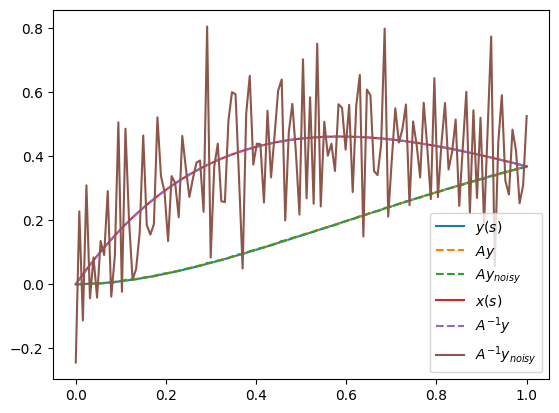

In [3]:
def y(s):
    return s**2 * np.exp(-s)

def x(s):
    return 2 * s * np.exp(-s) + s**2 * np.exp(-s) * (-1)

# Construct grid
N = 128
noise_level = 0.001
h = 1.0 / N
s = np.linspace(0, 1, N)

xvec = x(s)
# Backward Euler
A = np.tril(np.ones(N)) * h

yfwd = A @ xvec
yfwd_noisy = yfwd + noise_level * np.random.randn(*yfwd.shape)

xbwk = np.linalg.solve(A, yfwd)
xbwk_noisy = np.linalg.solve(A, yfwd_noisy)

plt.plot(s, y(s), label='$y(s)$')
plt.plot(s, yfwd, "--", label='$Ay$')
plt.plot(s, yfwd_noisy, "--", label='$Ay_{noisy}$')
plt.plot(s, x(s), label='$x(s)$')
plt.plot(s, xbwk, "--", label='$A^{-1}y$')
plt.plot(s, xbwk_noisy, label='$A^{-1}y_{noisy}$')
plt.legend()

#

Conclusions:

1. The inverse problem is extremely sensitive to noise
   1. This makes sense given the naive solution without regularisation where the noise level is significant as soon as it is of similar order to the gradient in $y$
2. The inverse problem sensitivity scales inversely with the number of sampling points
   1. This makes sense given that this effectively is increasing the "gradient" in $y$

# Abel Integral

$$
Kx(t) = \int_0^1 k(t, s) x(s) ds, \quad t>0, \quad k(t, s) = 
\begin{cases}
\frac{1}{\sqrt(t-s)}, \quad s <t\\
0, \quad s > t\\
\end{cases}
$$

Inverse problem:
- From $y = Kx$ find $x$

# Abel Problem

C:\Users\jeppe\AppData\Local\Temp\ipykernel_1720\2221496161.py:2: RuntimeWarning: invalid value encountered in sqrt
  return np.where(s < t, 1.0 / np.sqrt(t - s), 0.0)


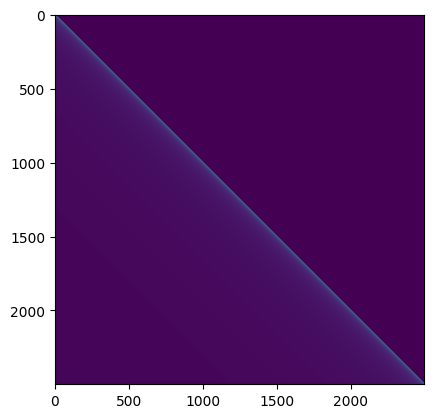

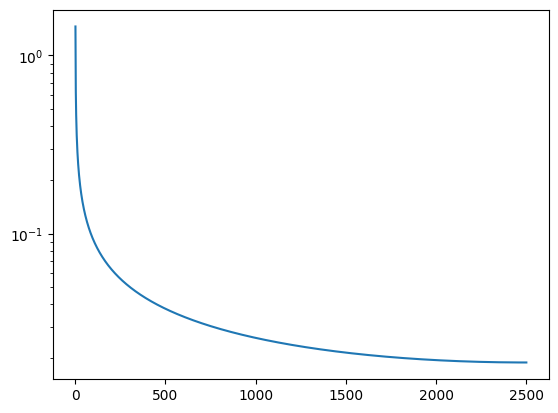

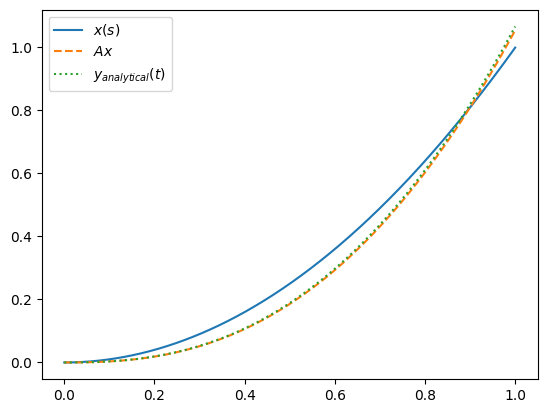

In [4]:
def k(t, s):
    return np.where(s < t, 1.0 / np.sqrt(t - s), 0.0)

nu = 2.0

def x(s):
    return s**nu

def y(t):
    return scipy.special.beta(nu+1, 0.5) * t**(nu + 0.5)


# Construct grid
N = 2500
noise_level = 0.001
h = 1.0 / N


s = h * np.arange(0.5, N)
t = h * np.arange(1, N+1)
# t = s
s_mesh, t_mesh = np.meshgrid(s, t)

A = h * k(t_mesh, s_mesh)
plt.figure()
plt.imshow(A)

U, S, V = np.linalg.svd(A)

plt.figure()
plt.plot(np.arange(len(S)) + 1, S)
plt.yscale("log")

x_vec = x(s)
y_quad = A @ x_vec
y_anal = y(t)

plt.figure()
plt.plot(s, x_vec, label='$x(s)$')
plt.plot(s, y_quad, "--", label='$Ax$')
plt.plot(s, y_anal, ":", label='$y_{analytical}(t)$')
plt.legend()

# A = np.tril(np.ones(N)) * h

# yfwd = A @ xvec
# yfwd_noisy = yfwd + noise_level * np.random.randn(*yfwd.shape)

# xbwk = np.linalg.solve(A, yfwd)
# xbwk_noisy = np.linalg.solve(A, yfwd_noisy)

# plt.plot(s, y(s), label='$y(s)$')
# plt.plot(s, yfwd, "--", label='$Ay$')
# plt.plot(s, yfwd_noisy, "--", label='$Ay_{noisy}$')
# plt.plot(s, x(s), label='$x(s)$')
# plt.plot(s, xbwk, "--", label='$A^{-1}y$')
# plt.plot(s, xbwk_noisy, label='$A^{-1}y_{noisy}$')
# plt.legend()

#

# Heat Equation

c:\Users\jeppe\Documents\MEGA\Base\DTU\02624 Inverse Problems and Imaging\.venv\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\jeppe\Documents\MEGA\Base\DTU\02624 Inverse Problems and Imaging\.venv\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


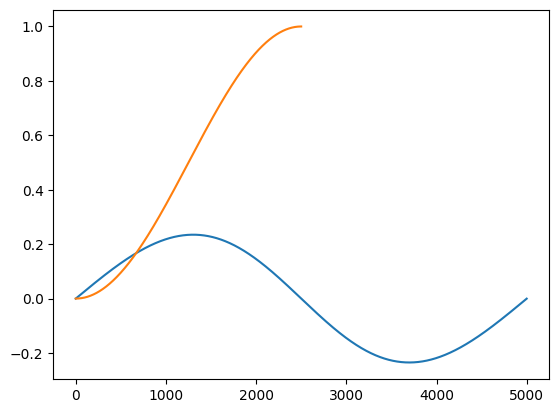

In [5]:
N = 2500
k = np.arange(-N, N)
k = np.fft.fftshift(k)

s = h * np.arange(0.5, N)
t = h * np.arange(1, N+1)

u0 = np.sin(np.pi * s / 2) ** 2
u = u0[1:]
u_ext = np.concatenate(([0], u, [0], -np.flip(u)))

u_hat = np.fft.fft(u_ext)
T = t[-1]
u_hatT = u_hat * np.exp(-k ** 2 * T)
uend = np.fft.ifft(u_hatT)
plt.plot(uend)
plt.plot(u0)

def x(s):
    return s**nu

def y(t):
    return scipy.special.beta(nu+1, 0.5) * t**(nu + 0.5)


# Construct grid
noise_level = 0.001
h = 1.0 / N


# t = s
s_mesh, t_mesh = np.meshgrid(s, t)

# A = h * k(t_mesh, s_mesh)
# plt.figure()
# plt.imshow(A)

# U, S, V = np.linalg.svd(A)

# plt.figure()
# plt.plot(np.arange(len(S)) + 1, S)
# plt.yscale("log")

# x_vec = x(s)
# y_quad = A @ x_vec
# y_anal = y(t)

# plt.figure()
# plt.plot(s, x_vec, label='$x(s)$')
# plt.plot(s, y_quad, "--", label='$Ax$')
# plt.plot(s, y_anal, ":", label='$y_{analytical}(t)$')
# plt.legend()

# A = np.tril(np.ones(N)) * h

# yfwd = A @ xvec
# yfwd_noisy = yfwd + noise_level * np.random.randn(*yfwd.shape)

# xbwk = np.linalg.solve(A, yfwd)
# xbwk_noisy = np.linalg.solve(A, yfwd_noisy)

# plt.plot(s, y(s), label='$y(s)$')
# plt.plot(s, yfwd, "--", label='$Ay$')
# plt.plot(s, yfwd_noisy, "--", label='$Ay_{noisy}$')
# plt.plot(s, x(s), label='$x(s)$')
# plt.plot(s, xbwk, "--", label='$A^{-1}y$')
# plt.plot(s, xbwk_noisy, label='$A^{-1}y_{noisy}$')
# plt.legend()

#

In [6]:
u

array([8.88264133e-07, 2.46739907e-06, 4.83609836e-06, ...,
       9.99997533e-01, 9.99999112e-01, 9.99999901e-01], shape=(2499,))